<center><h1>Liang_Qian_HW6</h1></center>

Name: Qian Liang
<br>
Github Username: qliang21-77
<br>
USC ID: 968162000075

## 1. Tree-Based Methods

Import packages

In [99]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import time
from sklearn.impute import SimpleImputer

### (a) Download the APS Failure data

In [100]:
aps_test= pd.read_csv('aps_failure_test_set.csv', skiprows=20, na_values='na')
aps_test

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,2.000000e+01,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,6.800000e+01,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,2.120000e+02,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1.010000e+03,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,1.560000e+02,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15995,neg,81852,NaN,2.130706e+09,892.0,0.0,0.0,0.0,0.0,0.0,...,632658.0,273242.0,510354.0,373918.0,349840.0,317840.0,960024.0,25566.0,0.0,0.0
15996,neg,18,0.0,5.200000e+01,46.0,8.0,26.0,0.0,0.0,0.0,...,266.0,44.0,46.0,14.0,2.0,0.0,0.0,0.0,0.0,0.0
15997,neg,79636,NaN,1.670000e+03,1518.0,0.0,0.0,0.0,0.0,0.0,...,806832.0,449962.0,778826.0,581558.0,375498.0,222866.0,358934.0,19548.0,0.0,0.0
15998,neg,110,NaN,3.600000e+01,32.0,0.0,0.0,0.0,0.0,0.0,...,588.0,210.0,180.0,544.0,1004.0,1338.0,74.0,0.0,0.0,0.0


In [101]:
aps_training= pd.read_csv('aps_failure_training_set.csv', skiprows=20, na_values='na')
aps_training

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,neg,153002,NaN,6.640000e+02,186.0,0.0,0.0,0.0,0.0,0.0,...,998500.0,566884.0,1290398.0,1218244.0,1019768.0,717762.0,898642.0,28588.0,0.0,0.0
59996,neg,2286,NaN,2.130707e+09,224.0,0.0,0.0,0.0,0.0,0.0,...,10578.0,6760.0,21126.0,68424.0,136.0,0.0,0.0,0.0,0.0,0.0
59997,neg,112,0.0,2.130706e+09,18.0,0.0,0.0,0.0,0.0,0.0,...,792.0,386.0,452.0,144.0,146.0,2622.0,0.0,0.0,0.0,0.0
59998,neg,80292,NaN,2.130706e+09,494.0,0.0,0.0,0.0,0.0,0.0,...,699352.0,222654.0,347378.0,225724.0,194440.0,165070.0,802280.0,388422.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

- mean/meadia substituion: replace missing numerical values with th emean or meadian
- Forward fill/Backward fill: commonly used in time-series data, propagates the last known value forward or the next value backward
- Regression Imputation: predicts and fills missing values by a regression model
- KNN imputation: estimates missing values by finding the k-nearest data points

I choose to use mean substitution

In [102]:
X_train = aps_training.drop(columns=['class'])
y_train = aps_training['class']

X_test = aps_test.drop(columns=['class'])
y_test = aps_test['class']

# mean substituion
imputer = SimpleImputer(strategy='mean')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

#### (ii) Calculate the coefficient of variation

In [103]:

cv_df = pd.DataFrame({
    'Feature': X_train.columns,
    'CV': X_train.std() / X_train.mean()
})

cv_df = cv_df.reset_index(drop=True)
cv_df

,Feature,CV
0,aa_000,2.450938
1,ab_000,2.328400
2,ac_000,2.169767
3,ad_000,183.847620
4,ae_000,23.190937
...,...,...
165,ee_007,4.962483
166,ee_008,3.222010
167,ee_009,5.626979
168,ef_000,47.124953


#### (iii) Plot a correlation matrix

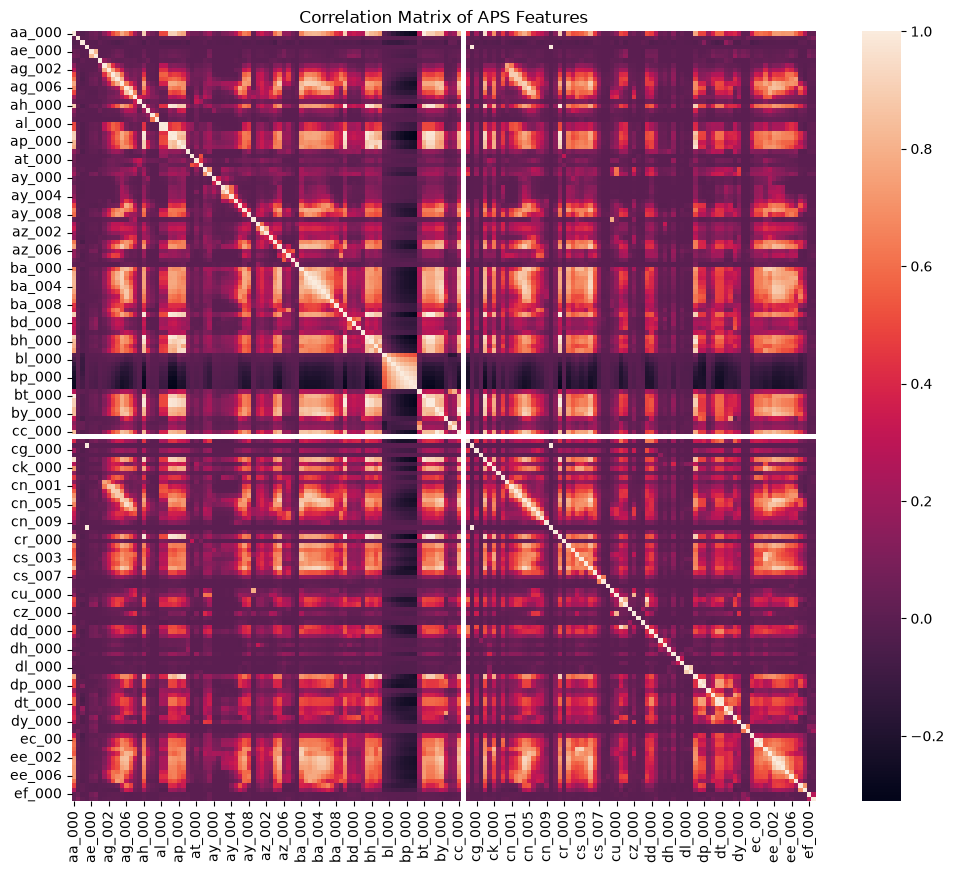

In [104]:
corr_matrix = X_train.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix)

plt.title('Correlation Matrix of APS Features')
plt.show()


#### (iv) Make scatter plots and box plots

In [105]:
top_13 = cv_df.sort_values(
    by='CV',
    ascending=False
).head(13)

top_13

,Feature,CV
122,cs_009,235.277605
91,cf_000,184.233092
109,co_000,183.949017
3,ad_000,183.847620
136,dh_000,114.984991
138,dj_000,109.647285
6,ag_000,91.878565
27,as_000,86.416904
41,ay_009,83.786063
51,az_009,76.967978


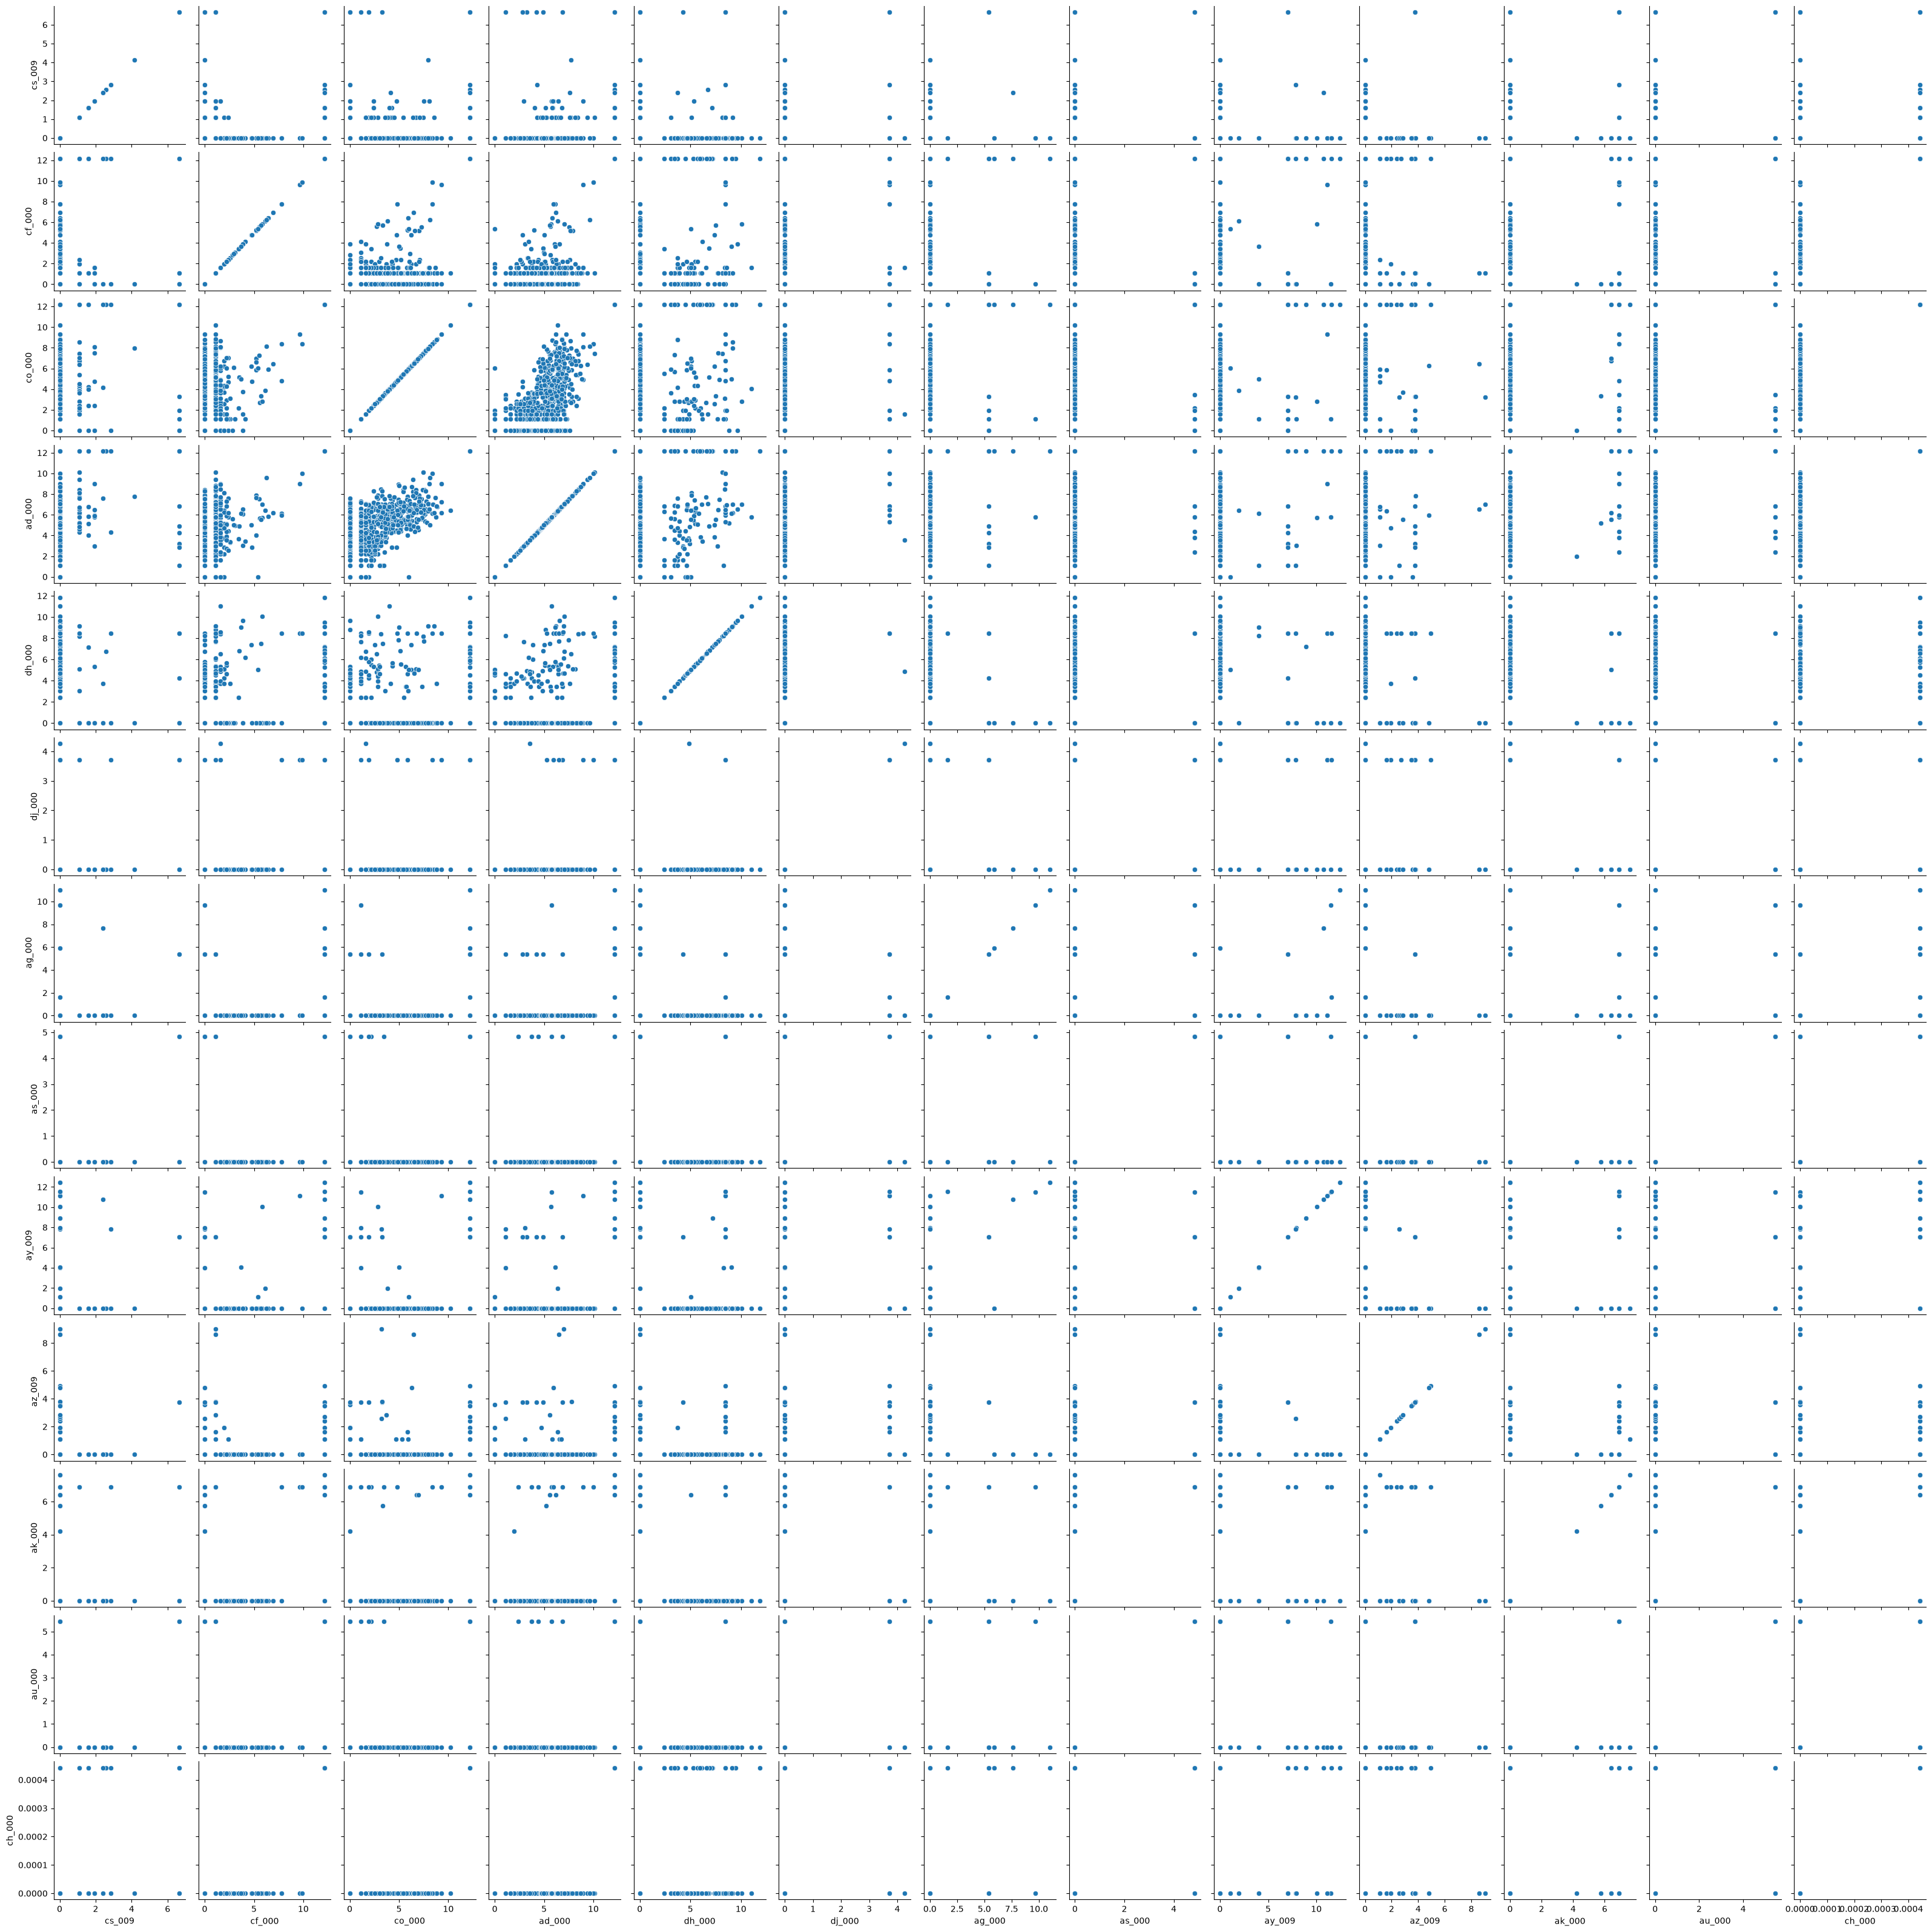

In [106]:
#scatter plot 
top_features = top_13['Feature']

sns.pairplot(
    data=np.log1p(
        X_train[top_features].sample(
            1000, random_state=42
        )
    ),
    diag_kind=None
)

plt.show()

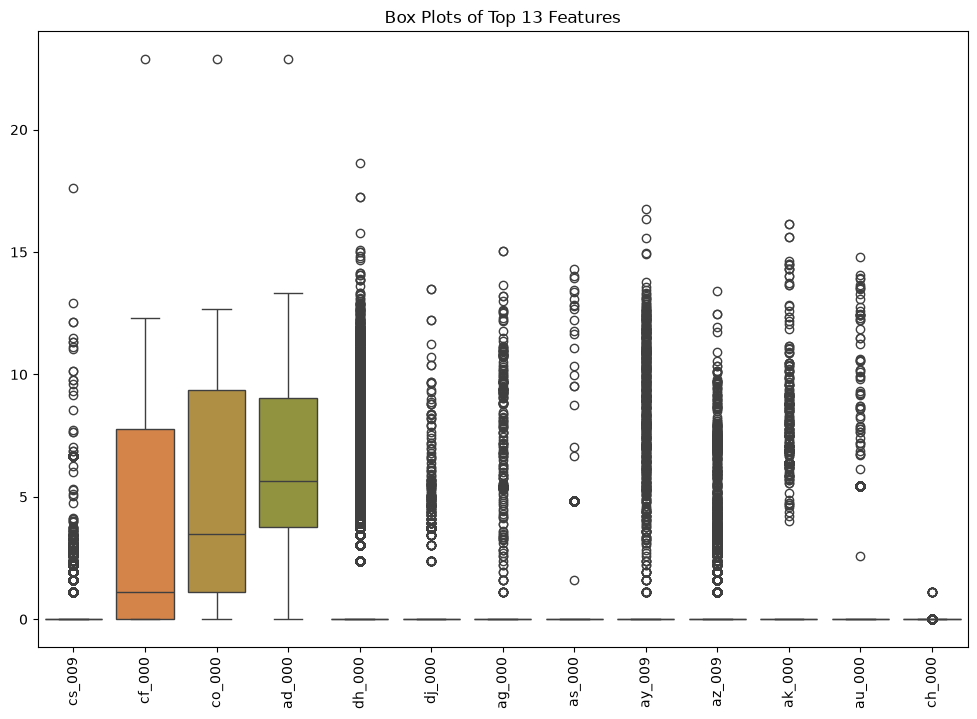

In [107]:
#boxplot 
plt.figure(figsize=(12, 8))

sns.boxplot(
    data=np.log1p(X_train[top_features])
)

plt.xticks(rotation=90)
plt.title('Box Plots of Top 13 Features')
plt.show()

- We cannot draw conclusion only by using scatterplot, since it does not show any relationship. 

#### (v) Is this data set imbalanced?

In [108]:
aps_training['class'].value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

- The data is highly imbalanced, there are significant more negative values than positive values. 

### (c) Train a random forest

In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score

In [110]:
#train a random forest
forest = RandomForestClassifier(
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

forest.fit(X_train, y_train)

y_pred_train = forest.predict(X_train)
y_pred_test = forest.predict(X_test)

In [111]:
# confusion matrix
cm_train = confusion_matrix(
    y_train, y_pred_train
)

cm_test = confusion_matrix(
    y_test, y_pred_test
)

print("Training Confusion Matrix:")
print(cm_train)

print("Testing Confusion Matrix:")
print(cm_test)

Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Testing Confusion Matrix:
[[15609    16]
 [  107   268]]


In [112]:
from sklearn.metrics import accuracy_score

train_error = 1 - accuracy_score(y_train, y_pred_train)
test_error = 1 - accuracy_score(y_test, y_pred_test)

print("Training Error:", train_error)
print("Testing Error:", test_error)


Training Error: 1.666666666666483e-05
Testing Error: 0.007687499999999958


In [113]:
oob_error = 1 - forest.oob_score_

print("OOB Error:", oob_error)
print("Test Error:", test_error)

OOB Error: 0.006000000000000005
Test Error: 0.007687499999999958


In [114]:
from sklearn.metrics import roc_curve, roc_auc_score
y_prob_train = forest.predict_proba(X_train)[:, 1]
y_prob_test = forest.predict_proba(X_test)[:, 1]

fpr_train, tpr_train, _ = roc_curve(
    y_train, y_prob_train, pos_label='pos'
)

fpr_test, tpr_test, _ = roc_curve(
    y_test, y_prob_test, pos_label='pos'
)

auc_train = roc_auc_score(
    y_train, y_prob_train
)

auc_test = roc_auc_score(
    y_test, y_prob_test
)

print("Training AUC:", auc_train)
print("Testing AUC:", auc_test)

Training AUC: 0.9999999999999999
Testing AUC: 0.9941591893333334


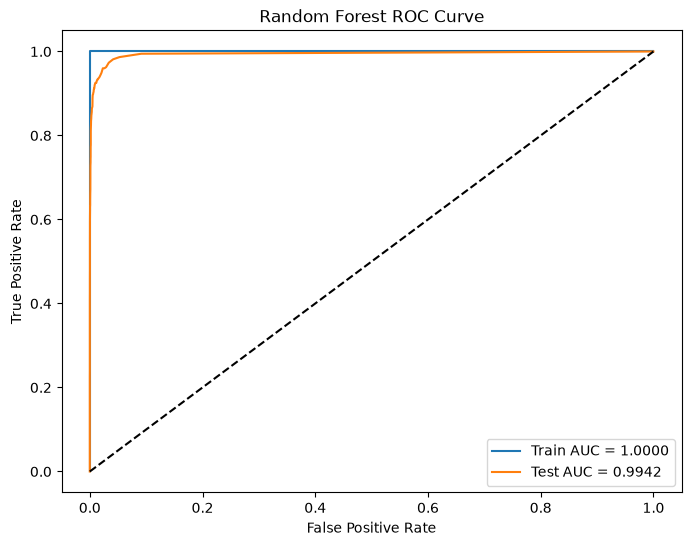

In [115]:
plt.figure(figsize=(8, 6))

plt.plot(fpr_train, tpr_train,
         label=f'Train AUC = {auc_train:.4f}')

plt.plot(fpr_test, tpr_test,
         label=f'Test AUC = {auc_test:.4f}')

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve')
plt.legend()
plt.show()

### (d) Research class imbalance in random forest

from https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf, there are two methods: 
- Weighted Random Forest : assigning more weight to minority class and less weight to majority class. Resulting in increase the penalty for misclassifying minority class observations. 
- Balanced Random Forest: uses random undersampling, which randomly select  samples from majority class to balance with the number of minority class samples.

I chose to use weight random method

In [116]:
forest_balanced = RandomForestClassifier(
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

forest_balanced.fit(X_train, y_train);
y_pred_train_balanced = forest_balanced.predict(X_train)
y_pred_test_balanced = forest_balanced.predict(X_test)

C:\Users\6fu\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


In [117]:
print("OOB Score:", forest_balanced.oob_score_)

print(confusion_matrix(
    y_test,
    y_pred_test_balanced,
    labels=['neg', 'pos']
))

OOB Score: 0.98005
[[15573    52]
 [   94   281]]


In [118]:
y_prob_train_balanced = forest_balanced.predict_proba(X_train)[:, 1]
y_prob_test_balanced = forest_balanced.predict_proba(X_test)[:, 1]

auc_train_balanced = roc_auc_score(
    y_train, y_prob_train_balanced
)

auc_test_balanced = roc_auc_score(
    y_test, y_prob_test_balanced
)

print("Training AUC:", auc_train_balanced)
print("Testing AUC:", auc_test_balanced)

Training AUC: 1.0
Testing AUC: 0.993072384


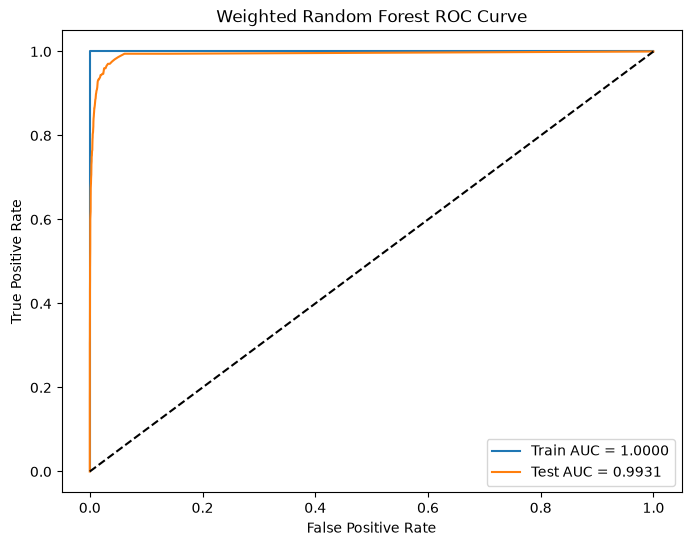

In [119]:
fpr_train_balanced, tpr_train_balanced, _ = roc_curve(
    y_train, y_prob_train_balanced, pos_label='pos'
)

fpr_test_balanced, tpr_test_balanced, _ = roc_curve(
    y_test, y_prob_test_balanced, pos_label='pos'
)

plt.figure(figsize=(8, 6))

plt.plot(fpr_train_balanced, tpr_train_balanced,
         label=f'Train AUC = {auc_train_balanced:.4f}')

plt.plot(fpr_test_balanced, tpr_test_balanced,
         label=f'Test AUC = {auc_test_balanced:.4f}')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Weighted Random Forest ROC Curve')
plt.legend()
plt.show()

In [120]:
rf_comparison = pd.DataFrame({
    'Original RF (1c)': [
        0.006, 1.0, 0.9941591893,
        15609, 16, 107, 268
    ],
    'Weighted RF (1d)': [
        0.01995, 1.0, 0.993072384,
        15573, 52, 94, 281
    ]
}, index=[
    'OOB Error',
    'Training AUC',
    'Testing AUC',
    'True Negatives (TN)',
    'False Positives (FP)',
    'False Negatives (FN)',
    'True Positives (TP)'
])

display(rf_comparison.round(4))

,Original RF (1c),Weighted RF (1d)
OOB Error,0.0060,0.0200
Training AUC,1.0000,1.0000
Testing AUC,0.9942,0.9931
True Negatives (TN),15609.0000,15573.0000
False Positives (FP),16.0000,52.0000
False Negatives (FN),107.0000,94.0000
True Positives (TP),268.0000,281.0000


Compared with the result in 1(c), the Weighted Random Forest in 1(d) has a higher OOB error and a lower testing AUC. Both models have a training AUC of 1.0.
Class weighting is a better predition, where the false positive increased from 16 to 52 and the false negative decreased from 107 to 94

### (e) XGBoost and Model Trees

In [121]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [122]:
y_train_xgb = (y_train == 'pos').astype(int)
y_test_xgb = (y_test == 'pos').astype(int)

print(y_train_xgb.value_counts())
print(y_test_xgb.value_counts())

class
0    59000
1     1000
Name: count, dtype: int64
class
0    15625
1      375
Name: count, dtype: int64


In [123]:
# Define alpha values
param_grid = {
    'reg_alpha': range(0, 11)
}

#  XGBoost
xgb = XGBClassifier(
    objective='binary:logistic',
    colsample_bytree=0.3,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    n_jobs=1
)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
gridcv = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

gridcv.fit(X_train, y_train_xgb);

In [124]:
best_alpha = gridcv.best_params_['reg_alpha']

cv_accuracy = gridcv.best_score_
cv_error = 1 - cv_accuracy

print("Best Alpha:", best_alpha)
print("CV Accuracy:", cv_accuracy)
print("CV Error:", cv_error)

Best Alpha: 0
CV Accuracy: 0.9937833333333332
CV Error: 0.006216666666666759


In [125]:

xgb_best = XGBClassifier(
    objective='binary:logistic',
    reg_alpha=best_alpha,
    colsample_bytree=0.3,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

xgb_best.fit(X_train, y_train_xgb);

y_pred_train_xgb = xgb_best.predict(X_train)
y_pred_test_xgb = xgb_best.predict(X_test)


print("Training Confusion Matrix:")
print(confusion_matrix(y_train_xgb, y_pred_train_xgb))

print("Testing Confusion Matrix:")
print(confusion_matrix(y_test_xgb, y_pred_test_xgb))


Training Confusion Matrix:
[[58993     7]
 [   89   911]]
Testing Confusion Matrix:
[[15604    21]
 [   94   281]]


In [126]:
y_prob_train_xgb = xgb_best.predict_proba(X_train)[:, 1]
y_prob_test_xgb = xgb_best.predict_proba(X_test)[:, 1]

auc_train_xgb = roc_auc_score(y_train_xgb, y_prob_train_xgb)
auc_test_xgb = roc_auc_score(y_test_xgb, y_prob_test_xgb)

print("Training AUC:", auc_train_xgb)
print("Testing AUC:", auc_test_xgb)


Training AUC: 0.9992289322033898
Testing AUC: 0.9952165546666667


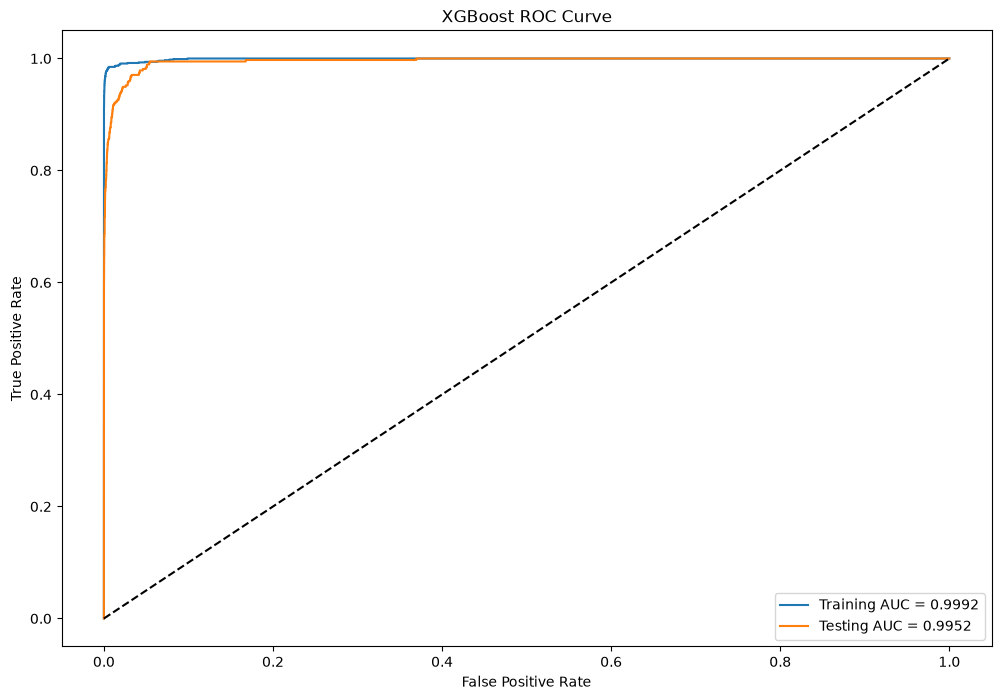

In [127]:
fpr_train, tpr_train, _ = roc_curve(
    y_train_xgb, y_prob_train_xgb
)

fpr_test, tpr_test, _ = roc_curve(
    y_test_xgb, y_prob_test_xgb
)

plt.figure(figsize=(12, 8))

plt.plot(fpr_train, tpr_train,
         label=f'Training AUC = {auc_train_xgb:.4f}')

plt.plot(fpr_test, tpr_test,
         label=f'Testing AUC = {auc_test_xgb:.4f}')

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curve')
plt.legend()
plt.show()


### (f) Use SMOTE to pre-process your data

In [128]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as imbpipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier


In [129]:
pipeline = imbpipeline(steps=[
    ('smote', SMOTE(random_state=5)),
    ('model', XGBClassifier(verbosity=0))
])

param_grid = {
    'model__reg_alpha': range(0, 11)
}

gridcv_smote = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy'
)

gridcv_smote.fit(X_train, y_train_xgb);

In [130]:
best_alpha_smote = gridcv_smote.best_params_['model__reg_alpha']

print("Best Alpha:", best_alpha_smote)
print("CV Accuracy:", gridcv_smote.best_score_)
print("CV Error:", 1 - gridcv_smote.best_score_)

Best Alpha: 0
CV Accuracy: 0.9937833333333334
CV Error: 0.006216666666666648


In [131]:
best_smote_xgb = gridcv_smote.best_estimator_

y_train_pred_smote = best_smote_xgb.predict(X_train)
y_test_pred_smote = best_smote_xgb.predict(X_test)

print("Training Confusion Matrix:")
print(confusion_matrix(y_train_xgb, y_train_pred_smote))

print("Testing Confusion Matrix:")
print(confusion_matrix(y_test_xgb, y_test_pred_smote))

print("Training Error:", 
      1 - best_smote_xgb.score(X_train, y_train_xgb))

print("Testing Error:", 
      1 - best_smote_xgb.score(X_test, y_test_xgb))

Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Testing Confusion Matrix:
[[15582    43]
 [   66   309]]
Training Error: 1.666666666666483e-05
Testing Error: 0.006812499999999999


In [132]:
y_train_prob_smote = best_smote_xgb.predict_proba(X_train)[:, 1]
y_test_prob_smote = best_smote_xgb.predict_proba(X_test)[:, 1]

train_auc_smote = roc_auc_score(y_train_xgb, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test_xgb, y_test_prob_smote)

print("Training AUC:", train_auc_smote)
print("Testing AUC:", test_auc_smote)

Training AUC: 0.999999220338983
Testing AUC: 0.9934977706666667


In [133]:
df = pd.DataFrame({
    'Train Error': [0.0016, 1/60000],
    'Train Accuracy': [1-0.0016, 1-1/60000],
    'Train ROC': [0.9992289, 0.9999992],
    'Test Error': [0.0071875, 0.0068125],
    'Test Accuracy': [1-0.0071875, 1-0.0068125],
    'Test ROC': [0.9952166, 0.9934978]
}, index=['Without SMOTE', 'With SMOTE'])
df

,Train Error,Train Accuracy,Train ROC,Test Error,Test Accuracy,Test ROC
Without SMOTE,0.001600,0.998400,0.999229,0.007188,0.992812,0.995217
With SMOTE,0.000017,0.999983,0.999999,0.006812,0.993188,0.993498


## 2. ISLR 6.6.3

a.  steady decrease due to less restriction and more flexibility causing overfittiing

b. Decrease initially, and then eventually start increasing in a U shape. When s initially increase, RSS decreases. but when s gets too large, model becomes too flexible and causing overfitting and RSS will increase.

c.  steady increase as s becomes large, model is more flexible and variance will increase

d. steady decrease as s becomes large, model is more flexible and bias will decrease

e. remain constant as irreducible error is unavoidable noise and will not be affected.

## 3. ISLR 6.6.5

a.

$x_{11}=x_{12}$ and $x_{21}=x_{22}$:


$$ 
(y_1 - \hat{\beta}_1x_{11} - \hat{\beta}_2 x_{12})^2
+ (y_2 - \hat{\beta}_1 x_{21} - \hat{\beta}_2 x_{22})^2
+ \lambda(\hat{\beta}_1^2 + \hat{\beta}_2^2)
$$

b. 

Taking the partial derivatives with respect to $\hat{\beta}_1$ and $\hat{\beta}_2$ and setting them equal to zero:

$$
\frac{\partial L}{\partial \hat{\beta}_1}
= -2x_{11}(y_1-\hat{\beta}_1x_{11}-\hat{\beta}_2x_{12})
-2x_{21}(y_2-\hat{\beta}_1x_{21}-\hat{\beta}_2x_{22})
+2\lambda\hat{\beta}_1=0
$$

$$
\frac{\partial L}{\partial \hat{\beta}_2}
= -2x_{12}(y_1-\hat{\beta}_1x_{11}-\hat{\beta}_2x_{12})
-2x_{22}(y_2-\hat{\beta}_1x_{21}-\hat{\beta}_2x_{22})
+2\lambda\hat{\beta}_2=0
$$

Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, subtracting the two equations gives:

$$
2\lambda\hat{\beta}_1-2\lambda\hat{\beta}_2=0
$$

$$
2\lambda(\hat{\beta}_1-\hat{\beta}_2)=0
$$


$$
\hat{\beta}_1=\hat{\beta}_2
$$





c. 
$$
(y_1-x_{11}(\hat{\beta}_1+\hat{\beta}_2))^2
+(y_2-x_{21}(\hat{\beta}_1+\hat{\beta}_2))^2
+\lambda(|\hat{\beta}_1|+|\hat{\beta}_2|)
$$

d. 

the absolution values gives +/- solutions, causing the coefficients not identical 

## 4. ISLR 8.4.5

- Majority Vote: Red given majority is classified as red
- Average Probability: Green given mean =0.45<0.5

## 5. ISLR 9.7.3

a

In [134]:
df = pd.DataFrame({
    'X1': [3, 2, 4, 1, 2, 4, 4],
    'X2': [4, 2, 4, 4, 1, 3, 1],
    'Y': ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']
}, index=range(1, 8))

df.index.name = 'Obs'
df

,X1,X2,Y
Obs,,,
1,3,4,Red
2,2,2,Red
3,4,4,Red
4,1,4,Red
5,2,1,Blue
6,4,3,Blue
7,4,1,Blue


<Axes: xlabel='X1', ylabel='X2'>

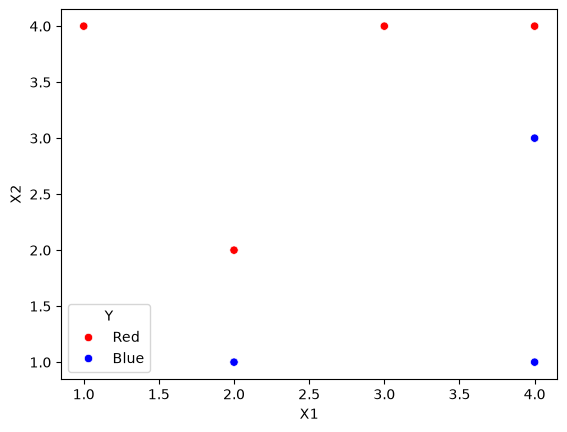

In [135]:
sns.scatterplot(data=df,  x='X1', y='X2', hue='Y',palette=['red','blue'])

b

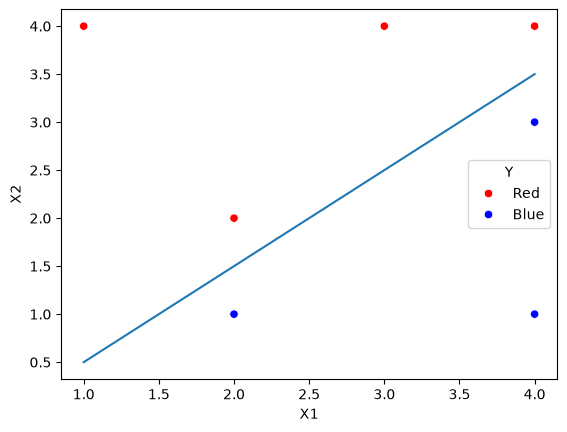

In [136]:
sns.scatterplot(data=df,  x='X1', y='X2', hue='Y',palette=['red','blue'])
x = [1, 2, 3, 4]
y = [a-0.5 for a in x]

plt.plot(x, y)
plt.show()

equation: x2=x1-0.5

c. red if X1-X2-0.5<0, otherwise blue

d.

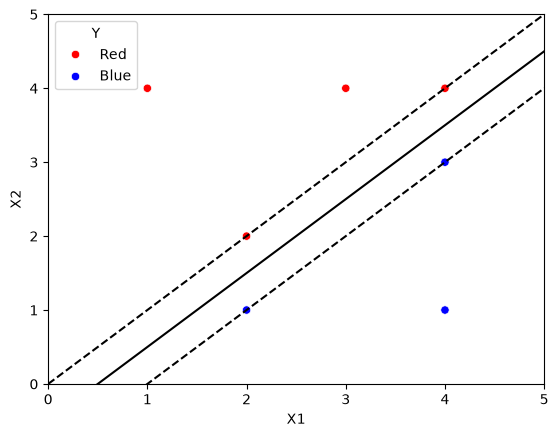

In [137]:

sns.scatterplot(data=df, x='X1', y='X2', hue='Y',
                palette={ 'red', 'blue'})

x = np.linspace(0, 5, 100)

plt.plot(x, x - 0.5, color='black')
plt.plot(x, x - 1, linestyle='--', color='black')
plt.plot(x, x, linestyle='--', color='black')

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.show()

e. red: (2,2),(4,4)
blue: (2,1),(4,3)

f. if remove (4,1), will not affect maximal margin hyperplane because it is not a support vector.

g. equation:  x2=x1-0.1

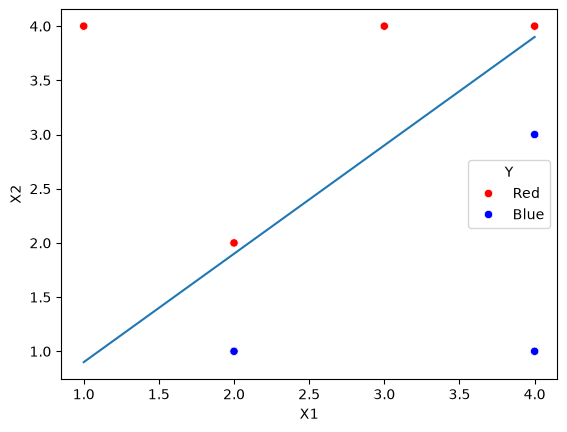

In [138]:

sns.scatterplot(data=df,  x='X1', y='X2', hue='Y',palette=['red','blue'])
x = [1, 2, 3, 4]
y = [a-0.1 for a in x]

plt.plot(x, y)
plt.show()

h. adding blue point (3,3)

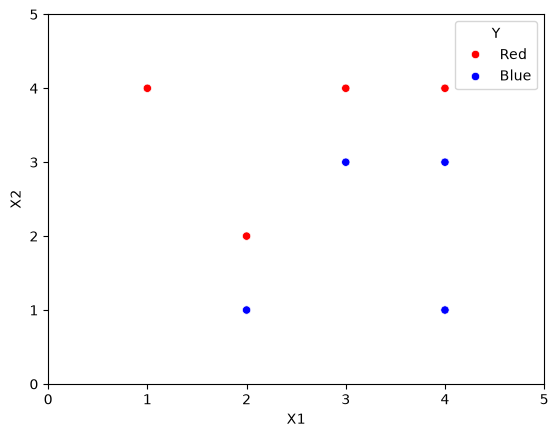

In [139]:
df_h = pd.concat([
    df,
    pd.DataFrame({'X1': [3], 'X2': [3], 'Y': ['Blue']}, index=[8])
])

sns.scatterplot(data=df_h, x='X1', y='X2', hue='Y',
                palette={'red', 'blue'})

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.show()

References:

- https://rpubs.com/ppaquay/65566
- https://www.geeksforgeeks.org/machine-learning/smote-for-imbalanced-classification-with-python/
- https://pmc.ncbi.nlm.nih.gov/articles/PMC11101000/
- https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf